# 08 — Partie F : tests de généralisation

Le test est descellé ici. Tous les choix (modèles, époques, `C`, seuils) ont été figés sur val avant cette étape (`scripts/run_F.py`).
Seuil unique choisi sur val pour chaque modèle ; seuil par valeur pour le NLI. Prédictions du test : `predictions/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2
from sklearn.metrics import f1_score
from valeval.data import VALUES, label_matrix, load_split
from valeval.evaluate import f1_par_valeur, scores

F = Path("../cache/final")
FAMILLES = {"Baseline TF-IDF": ("baseline_tfidf_lr", (0,)), "B1 NLI": ("B1_nli_deberta_large", (0,)),
            "C1 BiLSTM + GloVe": ("C1_bilstm_glove", (42, 43, 44)), "D1 RoBERTa gelé + LR": ("D1_roberta_gele_lr", (0,)),
            "D2 RoBERTa gelé + tête": ("D2_roberta_gele_bilstm_attention", (42, 43, 44)),
            "E1 RoBERTa fine-tuné": ("E1_roberta_ep8", (42, 43, 44)), "E2 multi-tâche (λ=0,3)": ("E2_roberta_lam0.3_ep8", (42, 43, 44))}
SPLITS = ["validation", "test", "test-nahjalbalagha", "test-nyt"]
donnees = {s: load_split(s) for s in SPLITS}
y = {s: label_matrix(df) for s, df in donnees.items()}

def seuil(nom, g):
    return np.array(json.loads((F / f"{nom}_seed{g}.json").read_text(encoding="utf-8"))["seuil"])

def proba(nom, g, s):
    return np.load(F / f"{nom}_seed{g}_{s}.npy")

lignes = []
for titre, (nom, graines) in FAMILLES.items():
    l = {"modèle": titre}
    for s in SPLITS:
        f = [scores(y[s], proba(nom, g, s) >= seuil(nom, g))["macro_f1"] for g in graines]
        l[s] = np.mean(f)
        if s == "test":
            l["écart-type test"] = np.std(f, ddof=1) if len(f) > 1 else np.nan
    lignes.append(l)
bilan = pd.DataFrame(lignes)
plancher = {"modèle": "« toutes les valeurs » (plancher)"}
plancher.update({s: scores(y[s], np.ones_like(y[s]))["macro_f1"] for s in SPLITS})
bilan = pd.concat([bilan, pd.DataFrame([plancher])], ignore_index=True)
bilan.to_csv("../results/F_bilan.csv", index=False)
bilan.round(3)

,modèle,validation,test,écart-type test,test-nahjalbalagha,test-nyt
0,Baseline TF-IDF,0.394,0.368,NaN,0.178,0.145
1,B1 NLI,0.427,0.405,NaN,0.214,0.170
2,C1 BiLSTM + GloVe,0.415,0.394,0.012,0.166,0.176
3,D1 RoBERTa gelé + LR,0.446,0.436,NaN,0.200,0.229
4,D2 RoBERTa gelé + tête,0.450,0.426,0.004,0.192,0.196
5,E1 RoBERTa fine-tuné,0.483,0.473,0.000,0.232,0.229
6,"E2 multi-tâche (λ=0,3)",0.482,0.469,0.001,0.229,0.218
7,« toutes les valeurs » (plancher),0.272,0.248,NaN,0.122,0.119


**Lecture :** le classement de val est conservé sur le test. E1 reste le meilleur (0,473 contre 0,483 sur val, soit -0,010). Tous les modèles perdent de 0,01 à 0,03 entre val et test, et le plancher « toutes les valeurs » lui-même baisse (0,272 → 0,248) : le test est un peu plus difficile pour tout le monde. Sur Nahj al-Balagha et NYT, tous les scores chutent de moitié environ.

## F1. Décalage de prior (Q10)
Fréquence de chaque valeur dans val et test, puis F1 par valeur sur le test avec le seuil de val (E1, 3 graines).

In [2]:
E1 = "E1_roberta_ep8"
GRAINES = (42, 43, 44)
parv = pd.DataFrame({"% val": y["validation"].mean(0) * 100, "% test": y["test"].mean(0) * 100}, index=VALUES)
parv["écart"] = parv["% test"] - parv["% val"]
f_va = pd.DataFrame([f1_par_valeur(y["validation"], proba(E1, g, "validation") >= seuil(E1, g)) for g in GRAINES]).mean()
f_te = pd.DataFrame([f1_par_valeur(y["test"], proba(E1, g, "test") >= seuil(E1, g)) for g in GRAINES]).mean()
parv["F1 val"], parv["F1 test"] = f_va, f_te
parv["Δ F1"] = parv["F1 test"] - parv["F1 val"]
print("corrélation (écart de fréquence, Δ F1) :", round(parv["écart"].corr(parv["Δ F1"]), 2))
print("valeurs par argument : val", y["validation"].sum(1).mean().round(2), "| test", y["test"].sum(1).mean().round(2))
print("oui prédits par argument (test, E1) :", round(np.mean([(proba(E1, g, "test") >= seuil(E1, g)).sum(1).mean() for g in GRAINES]), 2))
parv.sort_values("écart").round(3)

corrélation (écart de fréquence, Δ F1) : 0.42
valeurs par argument : val 3.35 | test 3.03
oui prédits par argument (test, E1) : 4.09


,% val,% test,écart,F1 val,F1 test,Δ F1
Benevolence: caring,33.386,21.320,-12.066,0.589,0.517,-0.072
Security: personal,40.032,34.074,-5.958,0.738,0.728,-0.010
Conformity: rules,23.998,18.211,-5.787,0.559,0.534,-0.026
Achievement,30.327,26.142,-4.185,0.651,0.563,-0.088
Self-direction: thought,13.238,9.074,-4.165,0.506,0.439,-0.067
Benevolence: dependability,14.135,10.343,-3.792,0.334,0.347,0.013
Hedonism,5.432,1.650,-3.783,0.456,0.220,-0.235
Stimulation,7.278,4.886,-2.393,0.363,0.245,-0.118
Humility,6.698,4.695,-2.003,0.205,0.184,-0.021
Power: dominance,8.650,6.853,-1.797,0.310,0.405,0.095


**Lecture (Q10) :**
- Le test compte moins de valeurs par argument (3,03 contre 3,35 sur val), mais E1 en prédit 4,09 : il dit « oui » trop souvent.
- Le décalage est très inégal selon la valeur : *Benevolence: caring* passe de 33,4 % à 21,3 %, *Universalism: objectivity* de 19,6 % à 29,9 %.
- Les valeurs devenues plus rares perdent du F1 (*Hedonism* : 5,4 % → 1,7 %, F1 0,456 → 0,220), celles devenues plus fréquentes en gagnent (*Universalism: nature*, *Tradition*). Corrélation entre écart de fréquence et écart de F1 : 0,42.

**Seuil de val et optimum a posteriori.** Analyse uniquement : aucun seuil n'est choisi sur le test.

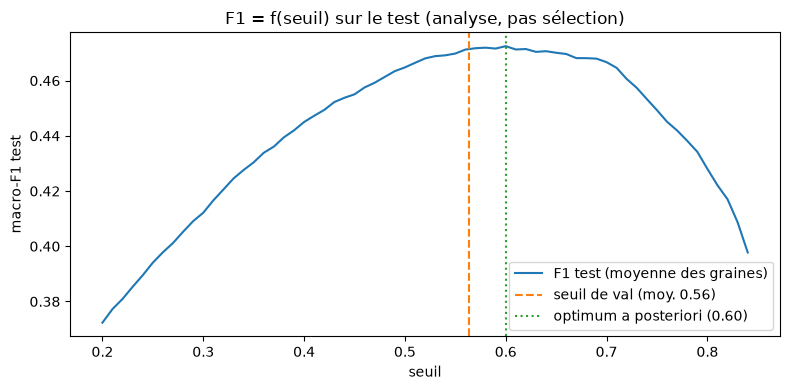

,graine,seuil val,F1 test au seuil val,seuil optimal test,F1 test optimal,perte
0,42,0.52,0.473,0.53,0.474,0.001
1,43,0.58,0.472,0.66,0.477,0.005
2,44,0.59,0.472,0.60,0.473,0.001


In [3]:
grille = np.arange(.20, .85, .01)
courbes = np.array([[f1_score(y["test"], proba(E1, g, "test") >= s, average="macro", zero_division=0) for s in grille] for g in GRAINES])
ecarts = []
for k, g in enumerate(GRAINES):
    i = courbes[k].argmax(); s = float(seuil(E1, g))
    ecarts.append({"graine": g, "seuil val": s, "F1 test au seuil val": scores(y["test"], proba(E1, g, "test") >= s)["macro_f1"],
                   "seuil optimal test": grille[i], "F1 test optimal": courbes[k, i]})
ecarts = pd.DataFrame(ecarts); ecarts["perte"] = ecarts["F1 test optimal"] - ecarts["F1 test au seuil val"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(grille, courbes.mean(0), label="F1 test (moyenne des graines)")
ax.axvline(ecarts["seuil val"].mean(), color="tab:orange", ls="--", label=f"seuil de val (moy. {ecarts['seuil val'].mean():.2f})")
ax.axvline(grille[courbes.mean(0).argmax()], color="tab:green", ls=":", label=f"optimum a posteriori ({grille[courbes.mean(0).argmax()]:.2f})")
ax.set(xlabel="seuil", ylabel="macro-F1 test", title="F1 = f(seuil) sur le test (analyse, pas sélection)")
ax.legend(); plt.tight_layout(); plt.savefig("../figures/F1_f1_vs_seuil_test.png", dpi=120); plt.show()
ecarts.round(3)

**Lecture (Q10) :** le seuil choisi sur val (0,52 à 0,59) est très proche de l'optimum a posteriori du test. La perte n'est que de 0,001 à 0,005 : malgré le décalage de prior, le **seuil global** reste bon. Ce qui change, c'est la fréquence de chaque valeur, que le seuil unique ne peut pas suivre.

**En production :** surveiller la part de « oui » prédits par valeur et la comparer à une petite fraction relabellisée chaque mois ; recalibrer les seuils quand l'écart dépasse un niveau fixé ; si la distribution des valeurs change franchement (nouveau domaine), réestimer les seuils sur un petit échantillon annoté de ce domaine.

## F2. Hors domaine (Q11)
Sur NYT (80 arguments), certaines valeurs n'ont aucun positif : leur F1 vaut 0 et fait baisser le macro-F1 quel que soit le modèle. On donne donc aussi le macro-F1 limité aux valeurs présentes.

In [4]:
def macro_presentes(yt, pred):
    garde = yt.sum(0) > 0
    return f1_score(yt[:, garde], pred[:, garde], average="macro", zero_division=0)

for s in ["test-nahjalbalagha", "test-nyt"]:
    print(s, "| valeurs sans positif :", [v for v, n in zip(VALUES, y[s].sum(0)) if n == 0], "| valeurs par argument :", y[s].sum(1).mean().round(2))
lignes = []
for titre, (nom, graines) in FAMILLES.items():
    l = {"modèle": titre}
    for s in SPLITS[1:]:
        l[s] = np.mean([macro_presentes(y[s], proba(nom, g, s) >= seuil(nom, g)) for g in graines])
    lignes.append(l)
l = {"modèle": "« toutes les valeurs » (plancher)"}
l.update({s: macro_presentes(y[s], np.ones_like(y[s])) for s in SPLITS[1:]})
lignes.append(l)
hd = pd.DataFrame(lignes); hd["chute Nahj"] = hd["test-nahjalbalagha"] - hd["test"]; hd["chute NYT"] = hd["test-nyt"] - hd["test"]
hd.round(3)

test-nahjalbalagha | valeurs sans positif : [] | valeurs par argument : 1.37
test-nyt | valeurs sans positif : ['Stimulation', 'Power: resources', 'Tradition'] | valeurs par argument : 1.39


,modèle,test,test-nahjalbalagha,test-nyt,chute Nahj,chute NYT
0,Baseline TF-IDF,0.368,0.178,0.171,-0.190,-0.197
1,B1 NLI,0.405,0.214,0.200,-0.191,-0.204
2,C1 BiLSTM + GloVe,0.394,0.166,0.207,-0.228,-0.187
3,D1 RoBERTa gelé + LR,0.436,0.200,0.270,-0.236,-0.166
4,D2 RoBERTa gelé + tête,0.426,0.192,0.230,-0.234,-0.196
5,E1 RoBERTa fine-tuné,0.473,0.232,0.269,-0.241,-0.203
6,"E2 multi-tâche (λ=0,3)",0.469,0.229,0.256,-0.240,-0.213
7,« toutes les valeurs » (plancher),0.248,0.122,0.140,-0.127,-0.109


In [5]:
dist = pd.DataFrame({s.replace("test-", ""): y[s].mean(0) * 100 for s in ["test", "test-nahjalbalagha", "test-nyt"]}, index=VALUES)
for s in ["test-nahjalbalagha", "test-nyt"]:
    dist["F1 " + s.replace("test-", "")] = pd.DataFrame([f1_par_valeur(y[s], proba(E1, g, s) >= seuil(E1, g)) for g in GRAINES]).mean()
print("oui prédits par argument (E1) :", {s: round(np.mean([(proba(E1, g, s) >= seuil(E1, g)).sum(1).mean() for g in GRAINES]), 2) for s in SPLITS[1:]})
print("médiane de la plus grande proba (E1) :", {s: round(float(np.median(proba(E1, 42, s).max(1))), 2) for s in SPLITS[1:]})
print("longueur moyenne de la prémisse (mots) :", {s: round(donnees[s].premise.str.split().str.len().mean(), 1) for s in SPLITS[1:]})
print("longueur moyenne de la conclusion (mots) :", {s: round(donnees[s].conclusion.str.split().str.len().mean(), 1) for s in SPLITS[1:]})
dist.round(2)

oui prédits par argument (E1) : {'test': np.float64(4.09), 'test-nahjalbalagha': np.float64(4.89), 'test-nyt': np.float64(4.3)}
médiane de la plus grande proba (E1) : {'test': 0.94, 'test-nahjalbalagha': 0.93, 'test-nyt': 0.91}
longueur moyenne de la prémisse (mots) : {'test': np.float64(21.6), 'test-nahjalbalagha': np.float64(20.4), 'test-nyt': np.float64(29.8)}
longueur moyenne de la conclusion (mots) : {'test': np.float64(5.7), 'test-nahjalbalagha': np.float64(5.6), 'test-nyt': np.float64(17.7)}


,test,nahjalbalagha,nyt,F1 nahjalbalagha,F1 nyt
Self-direction: thought,9.07,2.15,2.50,0.07,0.29
Self-direction: action,24.81,4.66,1.25,0.23,0.11
Stimulation,4.89,0.72,0.00,0.06,0.00
Hedonism,1.65,1.43,1.25,0.36,0.00
Achievement,26.14,25.45,16.25,0.61,0.42
Power: dominance,6.85,1.79,1.25,0.09,0.24
Power: resources,6.66,1.43,0.00,0.16,0.00
Face,6.09,13.26,2.50,0.51,0.10
Security: personal,34.07,23.66,33.75,0.37,0.52
Security: societal,25.19,2.87,11.25,0.17,0.39


In [6]:
from valeval.embeddings import charger_glove
from valeval.preprocess import corpus, Vocabulaire, SEP

g_mots = set(charger_glove()[0])
vocab = Vocabulaire(corpus(load_split("training")), min_freq=2)
lignes = []
for s in SPLITS[1:]:
    t = [m for texte in corpus(donnees[s]) for m in texte if m != SEP]
    lignes.append({"split": s, "OOV vocabulaire train (%)": 100 * np.mean([m not in vocab.indice for m in t]),
                   "OOV + GloVe (%)": 100 * np.mean([m not in vocab.indice and m not in g_mots for m in t])})
pd.DataFrame(lignes).round(2)

,split,OOV vocabulaire train (%),OOV + GloVe (%)
0,test,10.04,0.19
1,test-nahjalbalagha,10.90,0.12
2,test-nyt,14.60,0.09


In [7]:
pd.set_option("display.max_colwidth", 150)
for s in ["test-nahjalbalagha", "test-nyt"]:
    df = donnees[s].head(3)
    for i, r in zip(df.index, df.itertuples()):
        print(f"[{s}] {r.conclusion[:90]} | {r.stance} | {r.premise[:130]}")
        print("   vrai :", [v for v, b in zip(VALUES, y[s][i]) if b], "| prédit :", [v for v, b in zip(VALUES, proba(E1, 42, s)[i] >= seuil(E1, 42)) if b])

[test-nahjalbalagha] Habitual greed devalues humans | in favor of | Greed is like a slippery rock on which even the steps of scholars are not firm.
   vrai : ['Universalism: objectivity'] | prédit : ['Achievement', 'Conformity: rules', 'Benevolence: caring', 'Benevolence: dependability', 'Universalism: concern', 'Universalism: objectivity']
[test-nahjalbalagha] Habitual greed devalues humans | in favor of | Greedy people, in order to achieve their goal, must accept any humiliation and question everyone and give up their character in or
   vrai : ['Self-direction: action', 'Face'] | prédit : ['Face', 'Security: societal', 'Conformity: rules', 'Conformity: interpersonal', 'Benevolence: caring', 'Benevolence: dependability', 'Universalism: concern', 'Universalism: tolerance', 'Universalism: objectivity']
[test-nahjalbalagha] Habitual greed devalues humans | in favor of | Whoever adopts greed as a habit devalues himself
   vrai : ['Face'] | prédit : ['Face', 'Security: societal', 'Conformi

### Le problème vient-il du seuil ou du classement ?
Trois mesures pour E1 : le F1 au seuil de val, le F1 au meilleur seuil **a posteriori** (analyse, pas sélection), et la PR-AUC, indépendante du seuil. La PR-AUC moyenne d'un modèle au hasard vaut la fréquence moyenne des valeurs : on la donne pour comparer.

In [8]:
from sklearn.metrics import average_precision_score

lignes = []
for s in SPLITS[1:]:
    garde = y[s].sum(0) > 0
    yt = y[s][:, garde]
    p = [proba(E1, g, s)[:, garde] for g in GRAINES]
    lignes.append({"split": s, "F1 seuil val": np.mean([macro_presentes(yt, x >= float(seuil(E1, g))) for x, g in zip(p, GRAINES)]),
                   "F1 meilleur seuil a posteriori": np.mean([max(f1_score(yt, x >= t, average="macro", zero_division=0) for t in np.arange(.2, .96, .02)) for x in p]),
                   "PR-AUC": np.mean([average_precision_score(yt, x, average="macro") for x in p]), "PR-AUC du hasard": yt.mean(0).mean()})
pd.DataFrame(lignes).round(3)

,split,F1 seuil val,F1 meilleur seuil a posteriori,PR-AUC,PR-AUC du hasard
0,test,0.473,0.475,0.503,0.151
1,test-nahjalbalagha,0.232,0.237,0.247,0.069
2,test-nyt,0.269,0.322,0.408,0.082


**Lecture (Q11) :**
- **Chute :** pour E1, le macro-F1 (valeurs présentes) passe de 0,473 à **0,232 sur Nahj al-Balagha** et **0,269 sur NYT**. La baisse touche tous les modèles, de la baseline au fine-tuning.
- **Ce n'est pas un problème de vocabulaire :** avec GloVe, presque aucun mot n'est inconnu (0,12 % pour Nahj, 0,09 % pour NYT).
- **Ce sont surtout des valeurs différentes :** ces textes ont ~1,4 valeur par argument contre 3,0 au test, et une autre répartition (*Face* 13 % sur Nahj contre 6 % au test ; *Universalism: concern* 6 % contre 37 % ; *Security: societal* 3 % contre 25 %). E1 prédit pourtant ~4,9 valeurs par argument sur Nahj : il garde les habitudes du corpus d'entraînement.
- **Et un style différent :** sur Nahj, des maximes courtes et imagées traduites du persan ; sur NYT, des conclusions longues (17,7 mots contre 5,7), souvent des fragments de phrase d'un article.
- **Seuil ou classement ?** Sur NYT, un meilleur seuil aurait relevé le score (0,269 → 0,322) : une partie de la chute vient du seuil. Sur Nahj, presque rien (0,232 → 0,237) : le problème est le classement. La PR-AUC reste 3 à 5 fois au-dessus du hasard sur les deux jeux, mais elle est bien plus basse en valeur absolue, car les valeurs y sont plus rares.
- **Pour évaluer honnêtement un modèle avant un nouveau domaine :** annoter un petit échantillon de ce domaine, y mesurer le score et y régler les seuils, plutôt que de se fier au test d'origine.

## F3. Conclusion vue ou non vue
Aucune conclusion du test n'apparaît dans le train : le groupe « vue » est vide au sens exact. On utilise donc une notion de **sujet proche** : la similarité cosinus (RoBERTa gelé, moyenne des tokens) entre la conclusion et la conclusion du train la plus proche.

In [9]:
test = donnees["test"]
print("conclusions du test présentes dans le train :", len(set(test.conclusion) & set(load_split("training").conclusion)))
sim = np.load(F / "similarite_test.npy")
proches = pd.read_json(F / "voisins_test.json")
print(proches.drop_duplicates("conclusion").sort_values("similarite", ascending=False).head(4).to_string(index=False))
print(proches.drop_duplicates("conclusion").sort_values("similarite").head(4).to_string(index=False))
med = np.median(sim)
print("médiane :", round(float(med), 3))
lignes = []
for titre, (nom, graines) in FAMILLES.items():
    p = [(proba(nom, g, "test") >= seuil(nom, g)) for g in graines]
    lignes.append({"modèle": titre, "sujet proche": np.mean([macro_presentes(y["test"][sim >= med], x[sim >= med]) for x in p]),
                   "sujet éloigné": np.mean([macro_presentes(y["test"][sim < med], x[sim < med]) for x in p])})
f3 = pd.DataFrame(lignes); f3["écart"] = f3["sujet proche"] - f3["sujet éloigné"]
f3.round(3)

conclusions du test présentes dans le train : 0
                                                                   conclusion                                                                    voisin_train  similarite
We should have no immigration from non-European or non-first-world countries. There should be no immigration from non-European or non-first-world countries.        0.998
                                                  We should legalize polygamy                                                 We should legalize prostitution       0.997
              We should finally decide on the EU’s role in a multipolar world                             The EU should decide its role in a multipolar world       0.996
                                              We should subsidize print media                                                  We should subsidize journalism       0.993
                                                                              conclusion              

,modèle,sujet proche,sujet éloigné,écart
0,Baseline TF-IDF,0.373,0.336,0.037
1,B1 NLI,0.406,0.365,0.041
2,C1 BiLSTM + GloVe,0.389,0.373,0.016
3,D1 RoBERTa gelé + LR,0.446,0.392,0.054
4,D2 RoBERTa gelé + tête,0.426,0.403,0.023
5,E1 RoBERTa fine-tuné,0.482,0.427,0.055
6,"E2 multi-tâche (λ=0,3)",0.478,0.428,0.050


**Lecture :**
- Au sens exact, aucune conclusion du test n'est « vue » (0), par construction du jeu de données.
- Avec la similarité, les arguments au sujet proche du train obtiennent un meilleur score pour tous les modèles (+0,055 pour E1).
- **Prudence :** cette mesure est grossière. Toutes les similarités sont entre 0,97 et 1, et elle capte surtout la **forme** de la phrase (« We should legalize polygamy » est jugée presque identique à « We should legalize prostitution »). L'écart peut donc aussi refléter la source : les conclusions courtes en « We should… » viennent surtout du corpus IBM, majoritaire dans le train.

## F4. Retrait des mots-clés
Parmi les bonnes détections (argument, valeur) du test, on retire les mots-clés de **cette** valeur puis on reprédit au même seuil. Deux dictionnaires : train (`k` = 200) et descriptions. Graine 42 (baseline : unique).

In [10]:
lignes, detail = [], {}
for titre, nom, g in [("Baseline TF-IDF", "baseline_tfidf_lr", 0), ("C1 BiLSTM + GloVe", "C1_bilstm_glove", 42), ("E1 RoBERTa fine-tuné", E1, 42)]:
    r = json.loads((F / f"{nom}_seed{g}.json").read_text(encoding="utf-8"))["f4"]
    for d, l in r.items():
        t = pd.DataFrame(l)
        lignes.append({"modèle": titre, "dictionnaire": d, "détections": t.detectes.sum(), "conservées": t.restent.sum(),
                       "taux conservé": t.restent.sum() / t.detectes.sum(), "chute": 1 - t.restent.sum() / t.detectes.sum()})
        detail[(titre, d)] = t.assign(chute=1 - t.restent / t.detectes).set_index("valeur").chute
pd.DataFrame(lignes).round(3)

,modèle,dictionnaire,détections,conservées,taux conservé,chute
0,Baseline TF-IDF,train_k200,3095,2431,0.785,0.215
1,Baseline TF-IDF,descriptions,3095,2961,0.957,0.043
2,C1 BiLSTM + GloVe,train_k200,3180,2690,0.846,0.154
3,C1 BiLSTM + GloVe,descriptions,3180,3079,0.968,0.032
4,E1 RoBERTa fine-tuné,train_k200,3213,2783,0.866,0.134
5,E1 RoBERTa fine-tuné,descriptions,3213,3120,0.971,0.029


**Lecture :**
- Retirer les mots du **dictionnaire du train** fait perdre 13 % des bonnes détections d'E1, 15 % pour C1 et 21 % pour la baseline. Plus le modèle est riche, moins il dépend des mots-clés.
- Retirer les mots des **descriptions** ne coûte que 3 % : ces mots apparaissent rarement dans les arguments, comme vu en B2.
- Les valeurs les plus dépendantes des mots-clés pour E1 sont *Power: resources* (-43 %) et *Universalism: nature* (-41 %), qui ont un vocabulaire concret ; *Universalism: objectivity* ne perd que 3 %.

In [11]:
pd.DataFrame({"E1, train k=200": detail[("E1 RoBERTa fine-tuné", "train_k200")], "E1, descriptions": detail[("E1 RoBERTa fine-tuné", "descriptions")],
              "Baseline, train k=200": detail[("Baseline TF-IDF", "train_k200")]}).sort_values("E1, train k=200", ascending=False).round(3)

,"E1, train k=200","E1, descriptions","Baseline, train k=200"
valeur,,,
Power: resources,0.425,0.082,0.724
Universalism: nature,0.405,0.121,0.613
Self-direction: thought,0.303,0.056,0.511
Self-direction: action,0.218,0.048,0.256
Conformity: interpersonal,0.200,0.000,1.000
Universalism: tolerance,0.160,0.000,0.363
Security: societal,0.147,0.021,0.225
Universalism: concern,0.136,0.019,0.168
Power: dominance,0.133,0.017,0.200


## F5. Significativité
Bootstrap sur les arguments du test (1 000 tirages, IC à 95 %), et McNemar entre les deux meilleurs modèles sur val (E1, E2), puis E1 contre D1, modèle bien moins coûteux. Le McNemar porte sur les 20 décisions par argument : ces décisions ne sont pas indépendantes, donc on donne aussi l'IC bootstrap de l'écart de macro-F1, plus fiable.

In [12]:
def macro_rapide(yt, pr):
    tp = (yt & pr).sum(0); fp = (~yt & pr).sum(0); fn = (yt & ~pr).sum(0)
    return float(np.mean(2 * tp / np.maximum(2 * tp + fp + fn, 1)))

yb = y["test"].astype(bool)
rng = np.random.default_rng(42)
tirages = rng.integers(0, len(yb), (1000, len(yb)))
lignes, preds = [], {}
for titre, (nom, graines) in FAMILLES.items():
    g = graines[0]
    preds[titre] = proba(nom, g, "test") >= seuil(nom, g)
    b = [macro_rapide(yb[i], preds[titre][i]) for i in tirages]
    par_graine = [scores(y["test"], proba(nom, k, "test") >= seuil(nom, k))["macro_f1"] for k in graines]
    lignes.append({"modèle": titre, "moyenne des graines": np.mean(par_graine), "écart-type": np.std(par_graine, ddof=1) if len(graines) > 1 else np.nan,
                   "macro-F1 (1re graine)": macro_rapide(yb, preds[titre]), "IC 2,5 %": np.percentile(b, 2.5), "IC 97,5 %": np.percentile(b, 97.5)})
ic = pd.DataFrame(lignes)
ic.to_csv("../results/F5_intervalles.csv", index=False)
ic.round(3)

,modèle,moyenne des graines,écart-type,macro-F1 (1re graine),"IC 2,5 %","IC 97,5 %"
0,Baseline TF-IDF,0.368,NaN,0.368,0.355,0.381
1,B1 NLI,0.405,NaN,0.405,0.389,0.418
2,C1 BiLSTM + GloVe,0.394,0.012,0.407,0.393,0.419
3,D1 RoBERTa gelé + LR,0.436,NaN,0.436,0.423,0.448
4,D2 RoBERTa gelé + tête,0.426,0.004,0.425,0.409,0.439
5,E1 RoBERTa fine-tuné,0.473,0.000,0.473,0.459,0.486
6,"E2 multi-tâche (λ=0,3)",0.469,0.001,0.469,0.454,0.483


**Lecture :** E1 et E2 ont des intervalles qui se chevauchent largement ; E1 se détache nettement de D1, D2, C1, du NLI et de la baseline. Les écarts-types entre graines sont faibles (≤ 0,012).

In [13]:
def mcnemar(a, b):
    ok_a, ok_b = a == yb, b == yb
    n01, n10 = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    stat = (abs(n01 - n10) - 1) ** 2 / (n01 + n10)
    return n01, n10, stat, chi2.sf(stat, 1)

lignes = []
for x, z in [("E1 RoBERTa fine-tuné", "E2 multi-tâche (λ=0,3)"), ("E1 RoBERTa fine-tuné", "D1 RoBERTa gelé + LR"), ("E1 RoBERTa fine-tuné", "D2 RoBERTa gelé + tête")]:
    n01, n10, stat, p = mcnemar(preds[x], preds[z])
    d = [macro_rapide(yb[i], preds[x][i]) - macro_rapide(yb[i], preds[z][i]) for i in tirages]
    lignes.append({"comparaison": f"{x} / {z}", "seul le 1er a raison": n01, "seul le 2e a raison": n10, "chi2": stat, "p McNemar": p,
                   "écart F1": macro_rapide(yb, preds[x]) - macro_rapide(yb, preds[z]), "IC écart 2,5 %": np.percentile(d, 2.5), "IC écart 97,5 %": np.percentile(d, 97.5)})
pd.DataFrame(lignes).round(4)

,comparaison,seul le 1er a raison,seul le 2e a raison,chi2,p McNemar,écart F1,"IC écart 2,5 %","IC écart 97,5 %"
0,"E1 RoBERTa fine-tuné / E2 multi-tâche (λ=0,3)",539,974,124.4917,0.0000,0.0043,-0.0031,0.0114
1,E1 RoBERTa fine-tuné / D1 RoBERTa gelé + LR,2259,2010,14.4071,0.0001,0.0374,0.0252,0.0494
2,E1 RoBERTa fine-tuné / D2 RoBERTa gelé + tête,2421,2098,22.9440,0.0000,0.0484,0.0336,0.0620


**Lecture :**
- **E1 / E2 :** le test de McNemar donne p < 0,001 **en faveur d'E2** : E2 a raison seul sur 974 cases, E1 sur 539. Mais il compte les **cases** correctes (argument × valeur), dominées par les « non », comme l'accuracy écartée en Partie A. E2 prédit simplement moins de « oui ». Sur la métrique retenue, l'écart de macro-F1 vaut +0,004 en faveur d'E1, avec un IC à 95 % de [-0,003 ; +0,011] qui contient 0 : **aucune différence démontrée**.
- **E1 / D1 et E1 / D2 :** l'écart de macro-F1 (+0,037 et +0,048) a un IC entièrement positif : le fine-tuning apporte un gain réel.
- Les 20 décisions d'un même argument ne sont pas indépendantes, ce qui rend le McNemar par case trop optimiste. On s'appuie sur le bootstrap par argument.

## F6. Analyse de 30 erreurs (E1, graine 42)
Tirage aléatoire de couples (argument, valeur) mal classés : 20 du test (10 FN, 10 FP), 5 de Nahj al-Balagha, 5 de NYT. Classement fait à la main, une seule personne, avec justification ligne par ligne : `results/F6_erreurs.csv`. C'est un jugement, sur un petit échantillon.

In [14]:
err = pd.read_csv("../results/F6_erreurs.csv").fillna("")
print(pd.crosstab(err.categorie, err.split, margins=True).to_string())
print(); print(err.categorie.value_counts(normalize=True).mul(100).round(0).to_string())
print(); print("répartition des erreurs du test (E1, graine 42) : FN", int(((y["test"] == 1) & ~preds["E1 RoBERTa fine-tuné"]).sum()), "| FP", int(((y["test"] == 0) & preds["E1 RoBERTa fine-tuné"]).sum()))
err[["id", "type", "valeur", "proba", "categorie", "justification"]]

split                              test  test-nahjalbalagha  test-nyt  All
categorie                                                                 
argument ambigu                       5                   0         0    5
bruit d'annotation                    5                   1         2    8
style religieux ou journalistique     0                   3         2    5
valeur implicite                      4                   0         0    4
valeurs voisines                      6                   1         1    8
All                                  20                   5         5   30

categorie
bruit d'annotation                   27.0
valeurs voisines                     27.0
argument ambigu                      17.0
style religieux ou journalistique    17.0
valeur implicite                     13.0

répartition des erreurs du test (E1, graine 42) : FN 1558 | FP 3953


,id,type,valeur,proba,categorie,justification
0,A29184,FN,Security: personal,0.349,bruit d'annotation,Rien dans le texte ne renvoie à la sécurité personnelle ; le label surprend.
1,A32469,FN,Self-direction: thought,0.234,bruit d'annotation,"L'argument parle d'égalité des chances, pas de penser par soi-même."
2,A29215,FN,Universalism: objectivity,0.174,bruit d'annotation,Un coût de divorce ne relève pas de l'objectivité.
3,A32310,FN,Achievement,0.130,valeur implicite,"« Attraper plus de criminels » suppose l'efficacité, jamais nommée."
4,A31458,FN,Tradition,0.168,valeur implicite,"Les rôles traditionnels sont supposés, pas écrits."
5,A31455,FN,Hedonism,0.033,bruit d'annotation,« Sans victime » ne dit rien du plaisir.
6,A32368,FN,Achievement,0.245,valeur implicite,Le développement de l'enfant renvoie à la réussite de façon indirecte.
7,A29236,FN,Security: societal,0.509,valeurs voisines,"p = 0,51, juste sous le seuil : le modèle préfère Conformity: rules à Security: societal."
8,A31089,FN,Conformity: rules,0.261,valeur implicite,Réduire la délinquance implique le respect des règles sans le dire.
9,E01122,FN,Universalism: concern,0.424,argument ambigu,« Slogan vide » : le lien avec le souci de tous n'est pas clair.


**Croisement avec les doublons aux labels contradictoires (4.1).** Sur les paires du test, on compare une annotation à l'autre, puis le modèle à chaque annotation.

In [15]:
import re
def norm(x):
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", " ", x.lower())).strip()

t = donnees["test"].reset_index(drop=True)
cle = t.conclusion.map(norm) + "|" + t.stance + "|" + t.premise.map(norm)
paires = [g.index.tolist() for _, g in t[cle.duplicated(keep=False)].groupby(cle)]
a, b = [p[0] for p in paires], [p[1] for p in paires]
Y, P = y["test"], preds["E1 RoBERTa fine-tuné"].astype(int)
print("paires :", len(paires), "| labels identiques :", int((Y[a] == Y[b]).all(1).sum()))
print("accord humain (copie 1 / copie 2) : micro-F1", round(f1_score(Y[b], Y[a], average="micro"), 3))
print("modèle / copies (mêmes textes) : micro-F1", round(f1_score(np.r_[Y[a], Y[b]], np.r_[P[a], P[b]], average="micro"), 3))

paires : 32 | labels identiques : 4
accord humain (copie 1 / copie 2) : micro-F1 0.554
modèle / copies (mêmes textes) : micro-F1 0.493


**Lecture (Q12, partie erreurs) :**
- **Catégories dominantes :** bruit d'annotation (27 %) et valeurs voisines (27 %), puis argument ambigu et style religieux ou journalistique (17 % chacun), puis valeur implicite (13 %).
- **Hors domaine**, la moitié des erreurs tirées viennent du style (maximes, fragments d'article).
- **Part du bruit d'annotation :** ~27 % de l'échantillon, selon un seul annotateur, sur 30 erreurs : c'est un ordre de grandeur, pas une mesure précise.
- **Croisement avec les doublons :** sur les 32 paires du test, deux annotateurs humains ne s'accordent qu'à micro-F1 0,554 ; E1 atteint 0,493 face à ces mêmes annotations. Le modèle n'est pas loin de l'accord humain sur ces textes.
- Les FP sont 2,5 fois plus nombreux que les FN (3 953 contre 1 558), cohérent avec le surplus de « oui » observé en F1.